In [1]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
air_quality = fetch_ucirepo(id=360) 
data = air_quality.data

df = pd.DataFrame(data.features.copy())
# or, equivalently:
# df = air_quality.data.features.copy()
df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,3/10/2004,18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
1,3/10/2004,19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2,3/10/2004,20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
3,3/10/2004,21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
4,3/10/2004,22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [3]:
df.dtypes

Date                 str
Time                 str
CO(GT)           float64
PT08.S1(CO)        int64
NMHC(GT)           int64
C6H6(GT)         float64
PT08.S2(NMHC)      int64
NOx(GT)            int64
PT08.S3(NOx)       int64
NO2(GT)            int64
PT08.S4(NO2)       int64
PT08.S5(O3)        int64
T                float64
RH               float64
AH               float64
dtype: object

## Ubah Kolom Date dan Time menjadi Datetime dan indeks

In [4]:
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"])
df = df.drop(columns=["Date", "Time"])

df = df.sort_values('Datetime').set_index('Datetime')

df.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
Datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360,150,11.9,1046,166,1056,113,1692,1268,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292,112,9.4,955,103,1174,92,1559,972,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402,88,9.0,939,131,1140,114,1555,1074,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376,80,9.2,948,172,1092,122,1584,1203,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272,51,6.5,836,131,1205,116,1490,1110,11.2,59.6,0.7888


In [5]:
df.isna().sum()

CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64

In [6]:
df.replace(-200, np.nan, inplace=True)

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
Datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005-04-04 10:00:00,3.1,1314.0,NaN,13.5,1101.0,472.0,539.0,190.0,1374.0,1729.0,21.9,29.3,0.7568
2005-04-04 11:00:00,2.4,1163.0,NaN,11.4,1027.0,353.0,604.0,179.0,1264.0,1269.0,24.3,23.7,0.7119
2005-04-04 12:00:00,2.4,1142.0,NaN,12.4,1063.0,293.0,603.0,175.0,1241.0,1092.0,26.9,18.3,0.6406


In [7]:
df.isna().sum()

CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

In [8]:
print("Persentase persebaran nilai nan %")
(df.isna().sum() / len(df)) * 100

Persentase persebaran nilai nan %


CO(GT)           17.986534
PT08.S1(CO)       3.911510
NMHC(GT)         90.231912
C6H6(GT)          3.911510
PT08.S2(NMHC)     3.911510
NOx(GT)          17.516298
PT08.S3(NOx)      3.911510
NO2(GT)          17.548360
PT08.S4(NO2)      3.911510
PT08.S5(O3)       3.911510
T                 3.911510
RH                3.911510
AH                3.911510
dtype: float64

Buang kolom NMHC(GT) karena NaN > 90%


In [9]:
df = df.drop(columns=['NMHC(GT)'])

# Interpolasi berbasis waktu untuk gap yang pendek (misal maksimal 6 jam berturut-turut)

In [10]:
df = df.interpolate(method='time', limit=6)

In [11]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

imputer = IterativeImputer(random_state=42)
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns, index=df.index)

c:\Users\ahmdf\Documents\proyek-mingguan\week1\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [12]:
df_imputed.isna().sum()

CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64

In [13]:
df_imputed.describe()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,2.098326,1102.464321,10.174731,942.329712,236.621776,832.553357,109.319933,1455.097483,1029.107899,18.248697,49.240686,1.021683
std,1.445762,216.715203,7.436704,265.868048,207.535474,255.470045,47.312324,341.139429,400.599020,8.776710,17.165359,0.399802
min,0.039349,647.000000,0.100000,383.000000,-80.348365,53.708812,-6.639768,551.000000,221.000000,-3.478559,9.200000,0.154585
25%,1.000000,940.000000,4.600000,741.000000,92.000000,657.000000,74.000000,1238.000000,738.000000,11.800000,36.300000,0.739000
50%,1.731837,1066.000000,8.400000,913.000000,173.000000,806.000000,105.000000,1459.000000,968.000000,17.800000,49.400000,0.994100
75%,2.800000,1234.000000,14.100000,1117.000000,314.000000,966.000000,137.000000,1665.000000,1280.000000,24.200000,62.200000,1.300500
max,11.900000,2040.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,91.669197,2.231000


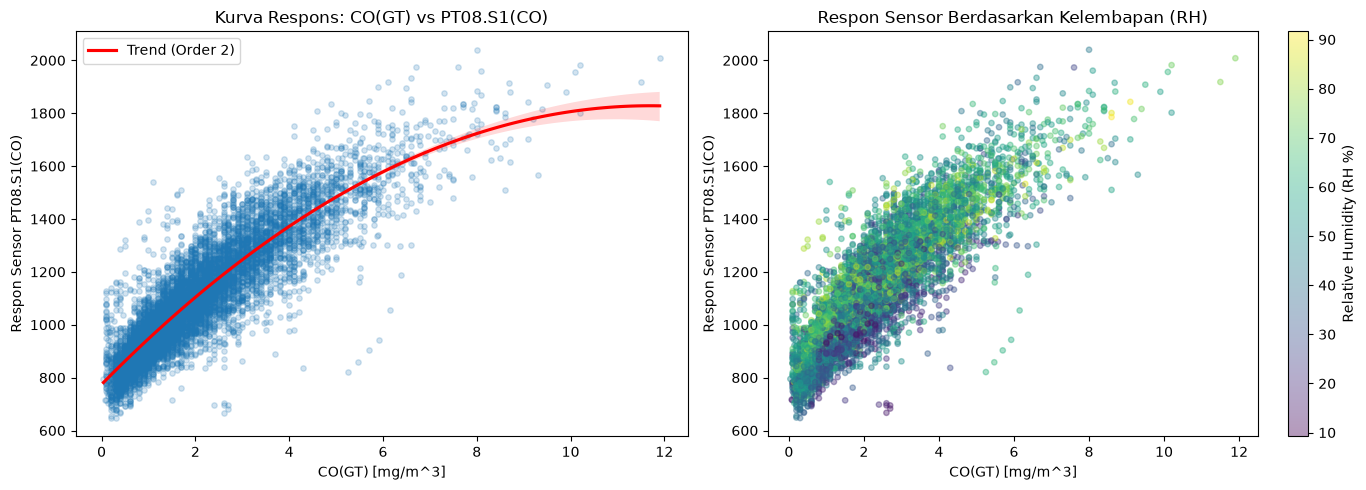

In [14]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Hubungan CO(GT) vs PT08.S1(CO) dengan kurva polinomial orde-2
sns.regplot(
    data=df_imputed, x='CO(GT)', y='PT08.S1(CO)',
    scatter_kws={'alpha': 0.2, 's': 15},
    line_kws={'color': 'red', 'label': 'Trend (Order 2)'},
    order=2, ax=axes[0]
)
axes[0].set_title('Kurva Respons: CO(GT) vs PT08.S1(CO)')
axes[0].set_xlabel('CO(GT) [mg/m^3]')
axes[0].set_ylabel('Respon Sensor PT08.S1(CO)')
axes[0].legend()

# Plot 2: Pengaruh Kelembapan (RH) terhadap pergeseran respon sensor
sc = axes[1].scatter(
    df_imputed['CO(GT)'], df_imputed['PT08.S1(CO)'],
    c=df_imputed['RH'], cmap='viridis', alpha=0.4, s=15
)
plt.colorbar(sc, ax=axes[1], label='Relative Humidity (RH %)')
axes[1].set_title('Respon Sensor Berdasarkan Kelembapan (RH)')
axes[1].set_xlabel('CO(GT) [mg/m^3]')
axes[1].set_ylabel('Respon Sensor PT08.S1(CO)')

plt.tight_layout()
plt.show()

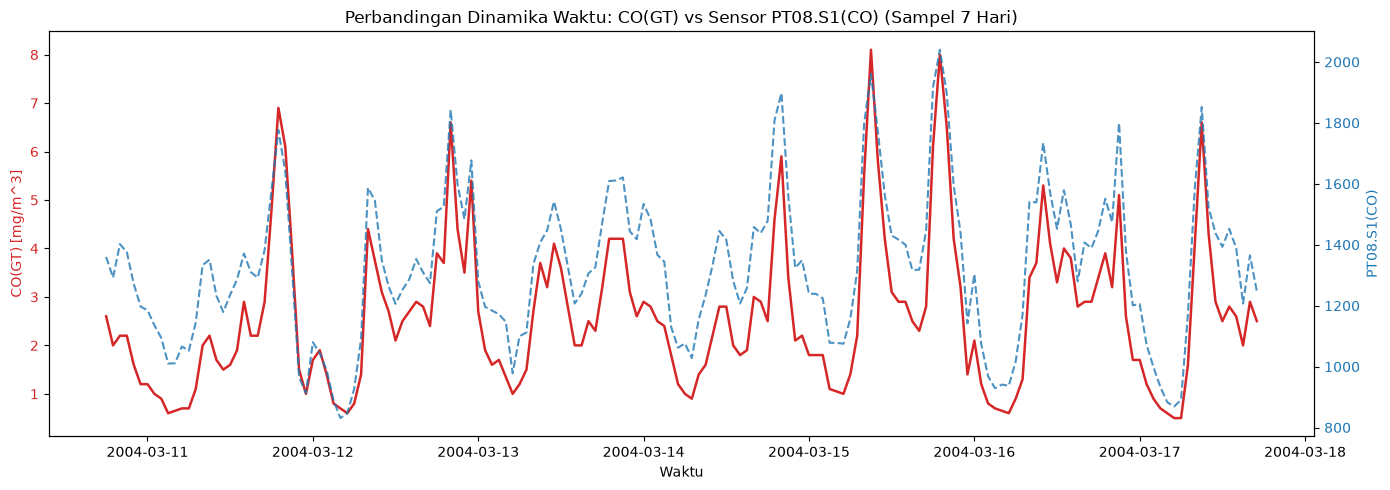

In [15]:
# Ambil sampel 7 hari (168 jam) agar grafik tidak terlalu padat
sample_df = df_imputed.iloc[:168]

fig, ax1 = plt.subplots(figsize=(14, 5))

# Sumbu Y kiri untuk CO(GT)
color1 = 'tab:red'
ax1.set_xlabel('Waktu')
ax1.set_ylabel('CO(GT) [mg/m^3]', color=color1)
ax1.plot(sample_df.index, sample_df['CO(GT)'], color=color1, linewidth=1.8, label='CO(GT)')
ax1.tick_params(axis='y', labelcolor=color1)

# Sumbu Y kanan untuk sensor PT08.S1(CO)
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('PT08.S1(CO)', color=color2)
ax2.plot(sample_df.index, sample_df['PT08.S1(CO)'], color=color2, linestyle='--', alpha=0.8, label='PT08.S1(CO)')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Perbandingan Dinamika Waktu: CO(GT) vs Sensor PT08.S1(CO) (Sampel 7 Hari)')
fig.tight_layout()
plt.show()

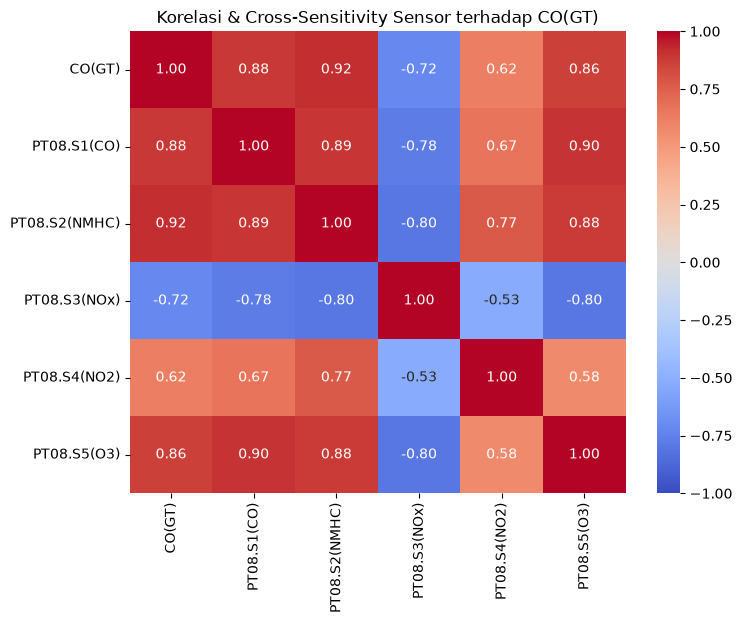

In [16]:
# Fokus pada CO(GT) dan seluruh sensor PT08
sensor_cols = ['CO(GT)', 'PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)']

plt.figure(figsize=(8, 6))
corr_matrix = df_imputed[sensor_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi & Cross-Sensitivity Sensor terhadap CO(GT)')
plt.show()

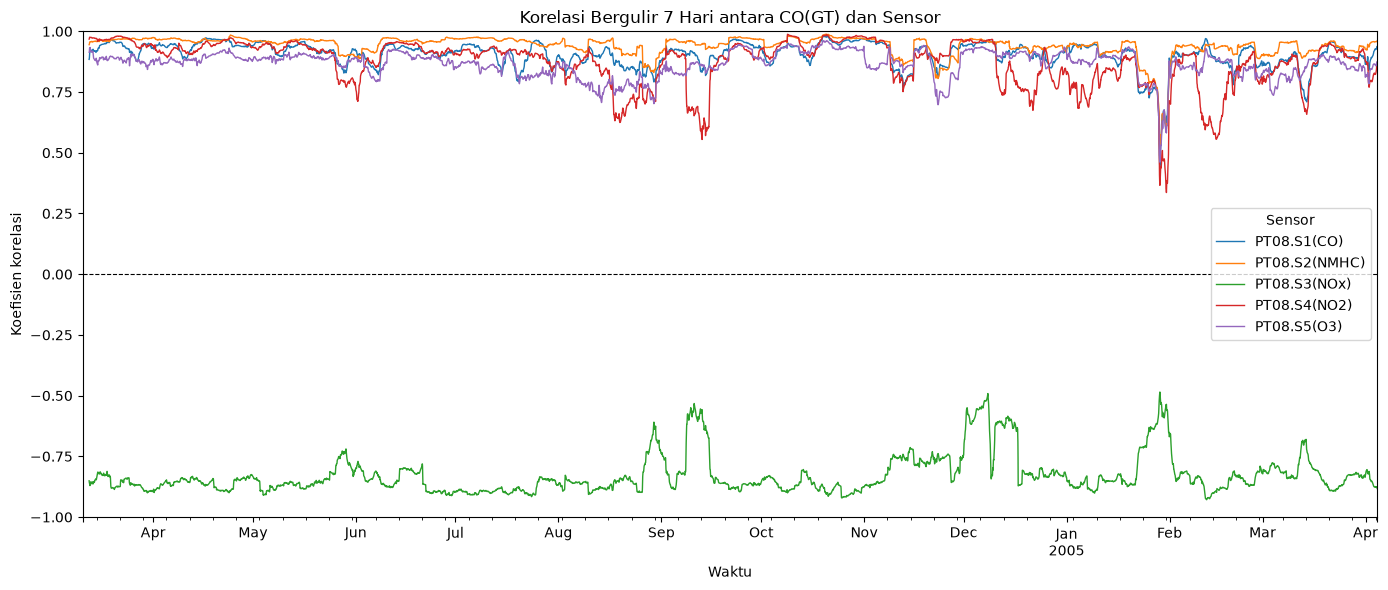

PT08.S2(NMHC)    0.958236
PT08.S1(CO)      0.937592
PT08.S5(O3)      0.873280
PT08.S4(NO2)     0.853746
PT08.S3(NOx)    -0.884062
Name: 2005-04-04 14:00:00, dtype: float64

In [17]:
# Korelasi bergulir 7 hari; minimal 48 observasi valid per jendela
rolling_corr = (
    df_imputed[sensor_cols[1:]]
    .rolling('7D', min_periods=48)
    .corr(df_imputed['CO(GT)'])
)

ax = rolling_corr.plot(figsize=(14, 6), linewidth=1)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Korelasi Bergulir 7 Hari antara CO(GT) dan Sensor')
ax.set_xlabel('Waktu')
ax.set_ylabel('Koefisien korelasi')
ax.set_ylim(-1, 1)
ax.legend(title='Sensor')
plt.tight_layout()
plt.show()

# Nilai korelasi pada jendela terakhir
rolling_corr.iloc[-1].sort_values(ascending=False)

In [18]:
df_imputed = df_imputed.sort_index()

split_index = int(len(df_imputed) * 0.7)

train_df = df_imputed.iloc[:split_index].copy()
test_df = df_imputed.iloc[split_index:].copy()

print(f"Ukuran Data Latih: {train_df.shape}, Ukuran Data Uji: {test_df.shape}")
print(f"ukuran data: {len(df_imputed)}")

Ukuran Data Latih: (6549, 12), Ukuran Data Uji: (2808, 12)
ukuran data: 9357


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train = train_df[["PT08.S1(CO)"]]
Y_train = train_df["CO(GT)"]

X_test = test_df[["PT08.S1(CO)"]]
Y_test = test_df["CO(GT)"]

model = LinearRegression()
model.fit(X_train, Y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(Y_test, y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, y_pred))
r2 = r2_score(Y_test, y_pred)

print(f"Intercept (b0) : {model.intercept_:.4f}")
print(f"Koefisien (b1) : {model.coef_[0]:.4f}")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²): {r2:.4f}")

Intercept (b0) : -4.4064
Koefisien (b1) : 0.0059
-----------------------------------
Mean Absolute Error (MAE): 0.5625
Root Mean Squared Error (RMSE): 0.7716
R-squared (R²): 0.7246


,MAE,RMSE,Jumlah
Datetime,,,
2004-12,0.644069,0.906697,561
2005-01,0.522064,0.758755,744
2005-02,0.459987,0.628962,672
2005-03,0.670311,0.825500,744
2005-04,0.252663,0.331287,87


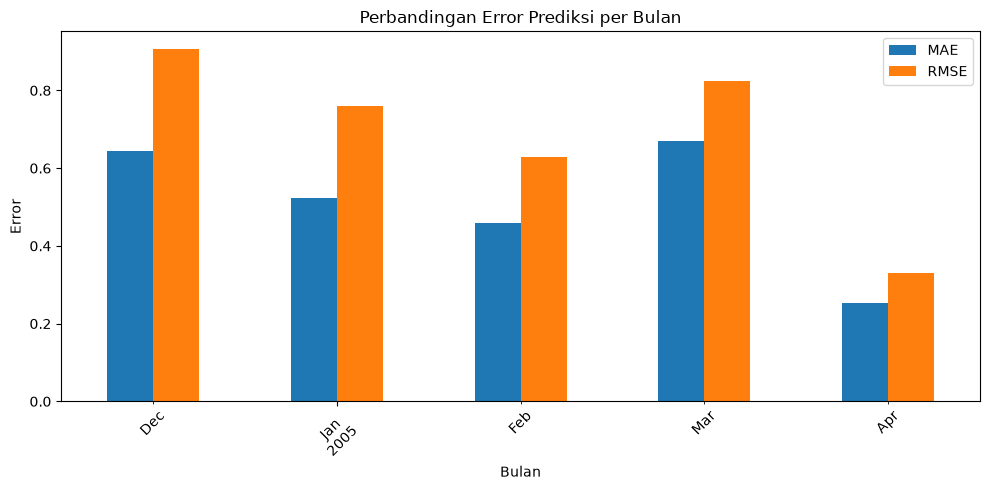

In [20]:
hasil = pd.DataFrame({
    "aktual": Y_test,
    "prediksi": y_pred
}, index=Y_test.index)

hasil["error"] = hasil["aktual"] - hasil["prediksi"]
hasil["absolute_error"] = hasil["error"].abs()
hasil["squared_error"] = hasil["error"] ** 2

error_bulanan = hasil.groupby(hasil.index.to_period("M")).agg(
    MAE=("absolute_error", "mean"),
    RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
    Jumlah=("error", "size")
)

display(error_bulanan)

error_bulanan[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(10, 5), rot=45
)
plt.title("Perbandingan Error Prediksi per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Error")
plt.tight_layout()
plt.show()